# Midterm. Baseline-модели

**Цель этапа:** для каждой из трёх задач обучить простую, но корректную модель, оценить её на **данных, которые модель не видела** (validation), и понять, что улучшать.

| Задача | Baseline | Опорная точка («без ML») | Метрики |
|---|---|---|---|
| A. Прогноз числа происшествий | линейный тренд (OLS) | seasonal naive: «как год назад» | MAE, RMSE |
| B. Риск организации | Poisson-регрессия | «как в прошлом месяце» | MAE, Poisson deviance |
| C. Тип по тексту | TF-IDF + логистическая регрессия | — | accuracy, macro-F1 |

Test (последние 6 месяцев / 15% текстов) **не используется**: его откроем один раз на финальном сравнении (A3).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import (load_raw, load_reference, clean_incidents, clean_korgau,
                      monthly_counts, INCIDENT_TYPES)
from src.features import build_org_month, split_period, FEATURES, TARGET
from src.forecast import seasonal_naive, TrendSeasonModel, mae, rmse
from src.nlp import split_texts, normalize
from src.plotting import set_style, TYPE_COLORS, KIND_COLORS, MAIN, MUTED, PALETTE

set_style()
pd.set_option("display.max_colwidth", 110)
np.random.seed(42)

inc_raw, kor_raw = load_raw()
incidents, _ = clean_incidents(inc_raw)
korgau, _ = clean_korgau(kor_raw)
orgs = load_reference("organizations")

## A. Прогноз месячного числа происшествий

**Метрики**
- **MAE** — средняя абсолютная ошибка, в происшествиях: «в среднем ошибаемся на N событий в месяц». Понятна HSE-специалисту.
- **RMSE** — корень из средней квадратичной ошибки. Сильнее штрафует крупные промахи. Если RMSE намного больше MAE, значит, есть отдельные большие ошибки.

Обе метрики указаны в критериях ТЗ (раздел 6: «MAE/RMSE прогноза»).

In [2]:
monthly = monthly_counts(incidents).astype(float)
part = split_period(pd.Series(monthly.index, index=monthly.index))
train_y, val_y = monthly[part == "train"], monthly[part == "val"]

baseline = TrendSeasonModel(harmonics=0, trend=True).fit(train_y)   # y = b0 + b1·t
print("Конфигурация baseline: OLS, признаки = [константа, номер месяца]")
print("Параметры:", dict(zip(["b0 (уровень)", "b1 (рост в месяц)"], baseline.result.params.round(2))))

pred_lin = baseline.predict(len(val_y))["forecast"].values
pred_naive = seasonal_naive(train_y, len(val_y))
res_a = pd.DataFrame({
    "MAE": [mae(val_y, pred_naive), mae(val_y, pred_lin)],
    "RMSE": [rmse(val_y, pred_naive), rmse(val_y, pred_lin)],
}, index=["seasonal naive (без обучения)", "линейный тренд (baseline)"]).round(2)
res_a

Конфигурация baseline: OLS, признаки = [константа, номер месяца]
Параметры: {'b0 (уровень)': np.float64(31.35), 'b1 (рост в месяц)': np.float64(0.59)}


,MAE,RMSE
seasonal naive (без обучения),12.83,13.97
линейный тренд (baseline),7.99,8.34


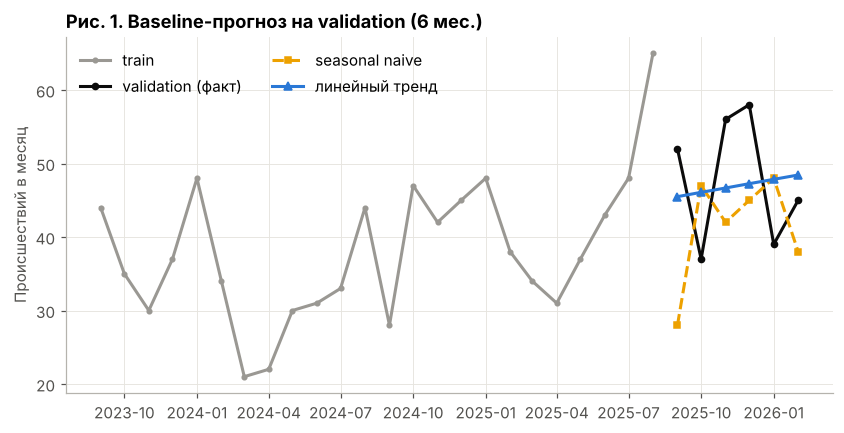

In [3]:
fig, ax = plt.subplots()
ax.plot(train_y.index, train_y, color=MUTED, marker="o", markersize=3, label="train")
ax.plot(val_y.index, val_y, color="#0b0b0b", marker="o", markersize=4, label="validation (факт)")
ax.plot(val_y.index, pred_naive, color=PALETTE[3], linestyle="--", marker="s", markersize=4, label="seasonal naive")
ax.plot(val_y.index, pred_lin, color=MAIN, marker="^", markersize=5, label="линейный тренд")
ax.set_ylabel("Происшествий в месяц"); ax.set_title("Рис. 1. Baseline-прогноз на validation (6 мес.)")
ax.legend(ncol=2); plt.show()

**Интерпретация.** «Как год назад» ошибается сильнее: ряд растёт, и прошлогодние значения систематически занижают прогноз. Линейный тренд это учитывает и сокращает ошибку. Чего он не умеет — сезонности: зимний пик он сглаживает. **Что улучшать:** добавить сезонную компоненту и сравнить несколько моделей (A3).

## B. Риск организации на следующий месяц

**Метрики**
- **MAE** — на сколько событий в среднем ошибаемся по организации за месяц.
- **Mean Poisson deviance** — штраф за то, насколько плохо предсказанная интенсивность λ объясняет фактическое число событий. Это «родная» метрика для счётных данных: она правильно наказывает, например, прогноз 0.1 при факте 3. Чем меньше, тем лучше.

In [4]:
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

om = build_org_month(incidents, korgau, orgs)
tr, va = om[om["split"] == "train"], om[om["split"] == "val"]

risk_baseline = Pipeline([("scale", StandardScaler()),
                          ("poisson", PoissonRegressor(alpha=1.0, max_iter=3000))])
risk_baseline.fit(tr[FEATURES], tr[TARGET])
print("Конфигурация:", risk_baseline.named_steps["poisson"].get_params(), "\nПризнаки:", FEATURES)

def risk_metrics(y, p):
    p = np.clip(p, 1e-3, None)
    return {"MAE": mean_absolute_error(y, p), "Poisson deviance": mean_poisson_deviance(y, p)}

res_b = pd.DataFrame({
    "«как в прошлом месяце»": risk_metrics(va[TARGET], va["inc_lag1"]),
    "Poisson-регрессия (baseline)": risk_metrics(va[TARGET], risk_baseline.predict(va[FEATURES])),
}).T.round(3)
res_b

Конфигурация: {'alpha': 1.0, 'fit_intercept': True, 'max_iter': 3000, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False} 
Признаки: ['inc_lag1', 'inc_mean3', 'bad_lag1', 'bad_share_lag1', 'overdue_lag1', 'is_contractor', 'headcount']


,MAE,Poisson deviance
«как в прошлом месяце»,2.262,6.085
Poisson-регрессия (baseline),1.691,1.618


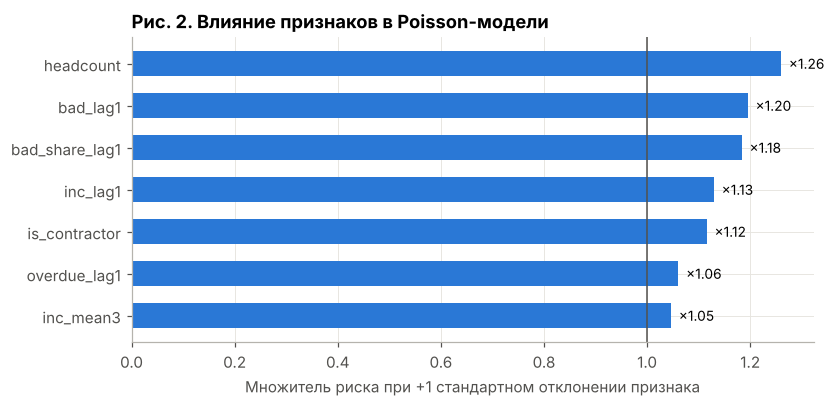

In [5]:
coef = pd.Series(np.exp(risk_baseline.named_steps["poisson"].coef_), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(coef.index, coef.values, color=[MAIN if v > 1 else MUTED for v in coef.values], height=.6)
ax.axvline(1, color="#52514e", linewidth=1)
for i, v in enumerate(coef.values):
    ax.text(v, i, f"  ×{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Множитель риска при +1 стандартном отклонении признака")
ax.set_title("Рис. 2. Влияние признаков в Poisson-модели")
plt.show()

**Интерпретация.** Наивный прогноз «как в прошлом месяце» сильно ошибается: число событий по организации шумное, один месяц — ненадёжная опора. Poisson-регрессия использует сразу несколько месяцев и нарушения Коргау, и её deviance заметно ниже. Все коэффициенты логичны: больше работников, больше нарушений, больше прошлых событий — выше риск. Доля плохих практик за прошлый месяц входит в число сильных признаков, что согласуется с гипотезой H1.

## C. Тип происшествия по тексту

**Метрики**
- **Accuracy** — доля верных ответов. При дисбалансе вводит в заблуждение: ответ «всегда опасная ситуация» даёт ≈ 67%.
- **Macro-F1** — F1 считается для каждого класса отдельно, затем усредняется **без весов**. Авария весит столько же, сколько опасная ситуация, поэтому метрика честно показывает качество на редких, но самых тяжёлых классах.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

train_txt, val_txt, test_txt = split_texts(incidents)
text_baseline = Pipeline([
    ("tfidf", TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), min_df=2)),
    ("logreg", LogisticRegression(max_iter=3000, random_state=42)),
])
text_baseline.fit(train_txt["description"], train_txt["type"])
pred = text_baseline.predict(val_txt["description"])
print("Размер словаря TF-IDF:", len(text_baseline.named_steps["tfidf"].vocabulary_))
res_c = pd.DataFrame({"accuracy": [accuracy_score(val_txt["type"], pred)],
                      "macro-F1": [f1_score(val_txt["type"], pred, average="macro")]},
                     index=["TF-IDF + LogReg (baseline)"]).round(3)
print(classification_report(val_txt["type"], pred, zero_division=0))
res_c

Размер словаря TF-IDF: 2251
                   precision    recall  f1-score   support

           Авария       0.00      0.00      0.00         3
      Микротравма       0.94      0.84      0.89        61
Несчастный случай       1.00      0.62      0.77         8
 Опасная ситуация       0.91      0.99      0.95       151

         accuracy                           0.92       223
        macro avg       0.71      0.61      0.65       223
     weighted avg       0.91      0.92      0.92       223



,accuracy,macro-F1
TF-IDF + LogReg (baseline),0.924,0.652


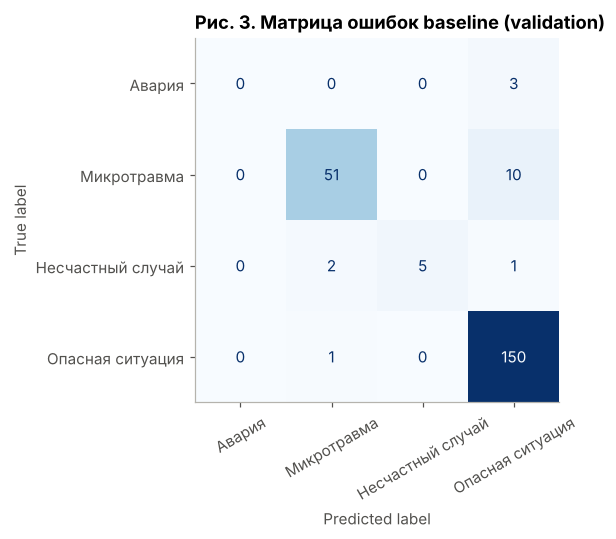

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(val_txt["type"], pred, ax=ax, cmap="Blues", colorbar=False,
                                        xticks_rotation=30)
ax.set_title("Рис. 3. Матрица ошибок baseline (validation)"); ax.grid(False)
plt.tight_layout(); plt.show()

**Интерпретация.** Accuracy высокая (≈ 92%), а macro-F1 всего ≈ 0.65. Модель **не нашла ни одной аварии**: все три она отнесла к опасным ситуациям. Несчастные случаи она частично путает с микротравмами. Логистическая регрессия без балансировки «подстраивается» под большинство. Именно эти ошибки самые дорогие: тяжёлое событие регистрируется как лёгкое и не попадает в расследование по форме Н-1. **Что улучшать:** балансировка классов (`class_weight`), подбор гиперпараметров, другие модели и pretrained-трансформер (A3).

## Сводная таблица baseline

In [8]:
summary = pd.concat({"A. Прогноз (мес.)": res_a, "B. Риск (орг.-мес.)": res_b, "C. Текст": res_c})
summary.round(3).astype(object).where(summary.notna(), "—")

MAE   RMSE  \
A. Прогноз (мес.)   seasonal naive (без обучения)  12.83  13.97   
                    линейный тренд (baseline)       7.99   8.34   
B. Риск (орг.-мес.) «как в прошлом месяце»         2.262      —   
                    Poisson-регрессия (baseline)   1.691      —   
C. Текст            TF-IDF + LogReg (baseline)         —      —   

                                                  Poisson deviance accuracy  \
A. Прогноз (мес.)   seasonal naive (без обучения)                —        —   
                    линейный тренд (baseline)                    —        —   
B. Риск (орг.-мес.) «как в прошлом месяце»                   6.085        —   
                    Poisson-регрессия (baseline)             1.618        —   
C. Текст            TF-IDF + LogReg (baseline)                   —    0.924   

                                                  macro-F1  
A. Прогноз (мес.)   seasonal naive (без обучения)        —  
                    линейный тренд (baseline)            —  
B. Риск (орг.-мес.) «как в прошлом месяце»               —  
                    Poisson-регрессия (baseline)         —  
C. Текст            TF-IDF + LogReg (baseline)       0.652

## Обоснование выбора baseline-моделей

| Задача | Почему эта модель | Какие свойства данных учтены | Альтернативы и почему пока нет |
|---|---|---|---|
| A | Линейный тренд — самая простая обучаемая модель, у которой есть параметры | в EDA найден рост ≈ 40% за 2 года | SARIMA, Holt-Winters: на 24 точках train сезонные модели рискуют переобучиться, сравним их в A3 |
| B | Poisson — стандартная модель для числа событий, коэффициенты интерпретируемы | target — счётный, неотрицательный, с дисперсией ≈ среднему | бустинг, случайный лес: сравним в A3, но они хуже объясняются |
| C | TF-IDF + LogReg — классический сильный baseline для коротких текстов | тексты короткие, много характерных слов-маркеров | трансформеры: дороже, проверим в A3 с fine-tuning и LoRA |

## Исследовательский вывод

1. **Что показал эксперимент.** Простые обучаемые модели уже лучше правил «без ML» в задачах A и B. В задаче C высокая accuracy скрывает провал на редких классах.
2. **Ограничения.** Validation — всего 6 месяцев (задача A) и 15% текстов (3 аварии), поэтому оценки шумные. Данные синтетические.
3. **Следующий эксперимент (A3):** A — добавить сезонность и сравнить с Holt-Winters и SARIMA через backtesting; B — подобрать регуляризацию и сравнить с бустингом, проверить H1 через абляцию (модель без признаков Коргау); C — балансировка классов, GridSearch, LinearSVC, fine-tuning трансформера и LoRA.